# 1. Import libraries and Load Dataset

In [7]:
# Settings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_olivetti_faces

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

roll_num = "M26CPS005" 
seed = int("".join([c for c in roll_num if c.isdigit()]))    # Igore alphabets and convert to integer

In [10]:
# load Datset

faces_df = fetch_olivetti_faces(shuffle= False)              # shuffle= False : images of the same person grouped.

X = faces_df.data
y = faces_df.target

print("Dataset shape = ", X.shape)
print("Labels shape = ", y.shape)

Dataset shape =  (400, 4096)
Labels shape =  (400,)


In [13]:
print(y)

[ 0  0  0  0  0  0  0  0  0  0  1  1  1  1  1  1  1  1  1  1  2  2  2  2
  2  2  2  2  2  2  3  3  3  3  3  3  3  3  3  3  4  4  4  4  4  4  4  4
  4  4  5  5  5  5  5  5  5  5  5  5  6  6  6  6  6  6  6  6  6  6  7  7
  7  7  7  7  7  7  7  7  8  8  8  8  8  8  8  8  8  8  9  9  9  9  9  9
  9  9  9  9 10 10 10 10 10 10 10 10 10 10 11 11 11 11 11 11 11 11 11 11
 12 12 12 12 12 12 12 12 12 12 13 13 13 13 13 13 13 13 13 13 14 14 14 14
 14 14 14 14 14 14 15 15 15 15 15 15 15 15 15 15 16 16 16 16 16 16 16 16
 16 16 17 17 17 17 17 17 17 17 17 17 18 18 18 18 18 18 18 18 18 18 19 19
 19 19 19 19 19 19 19 19 20 20 20 20 20 20 20 20 20 20 21 21 21 21 21 21
 21 21 21 21 22 22 22 22 22 22 22 22 22 22 23 23 23 23 23 23 23 23 23 23
 24 24 24 24 24 24 24 24 24 24 25 25 25 25 25 25 25 25 25 25 26 26 26 26
 26 26 26 26 26 26 27 27 27 27 27 27 27 27 27 27 28 28 28 28 28 28 28 28
 28 28 29 29 29 29 29 29 29 29 29 29 30 30 30 30 30 30 30 30 30 30 31 31
 31 31 31 31 31 31 31 31 32 32 32 32 32 32 32 32 32

In [29]:
pd.DataFrame(y).value_counts()

# there o to 39 class of people each with 10 images

0 
0     10
1     10
2     10
3     10
4     10
5     10
6     10
7     10
8     10
9     10
10    10
11    10
12    10
13    10
14    10
15    10
16    10
17    10
18    10
19    10
20    10
21    10
22    10
23    10
24    10
25    10
26    10
27    10
28    10
29    10
30    10
31    10
32    10
33    10
34    10
35    10
36    10
37    10
38    10
39    10
Name: count, dtype: int64

- Total 40 unique peoples
- Each with 10 images
- Each image of 4096 pixels(64*64)

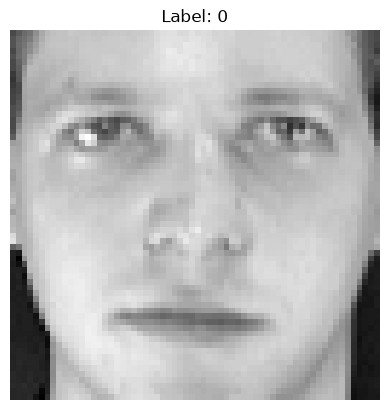

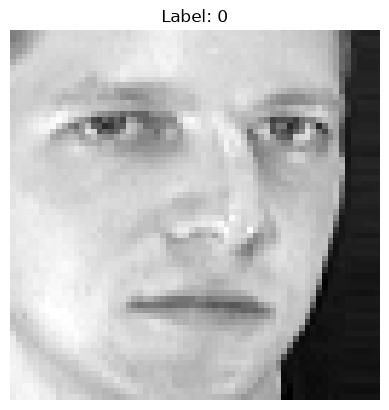

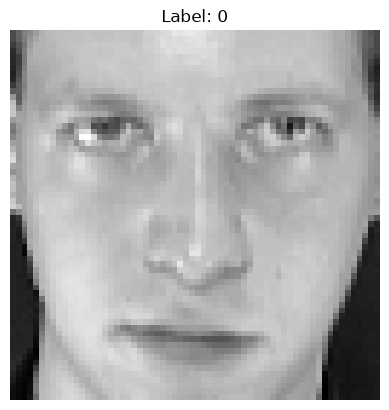

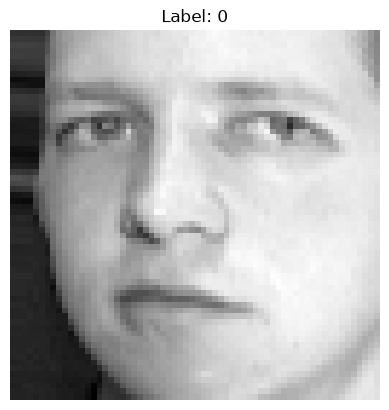

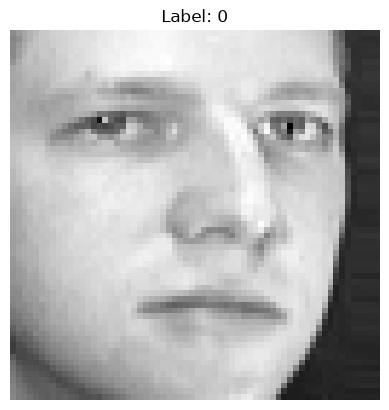

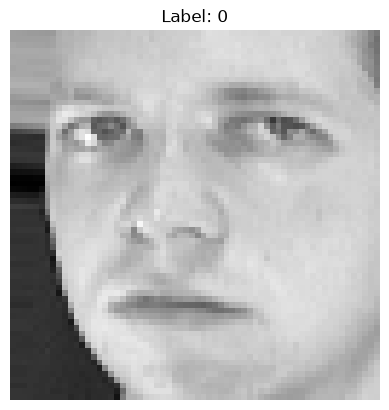

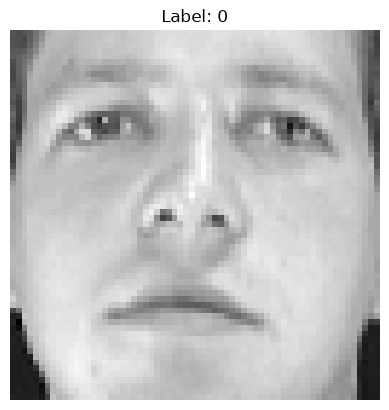

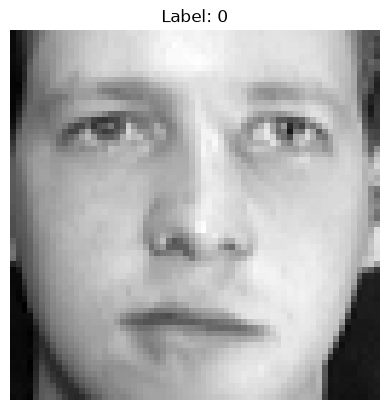

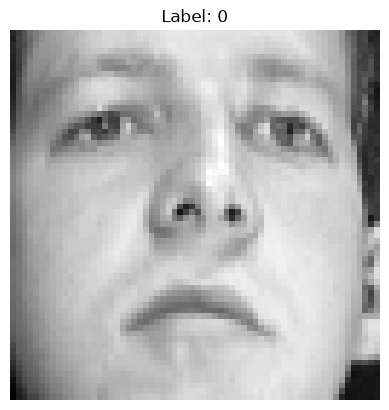

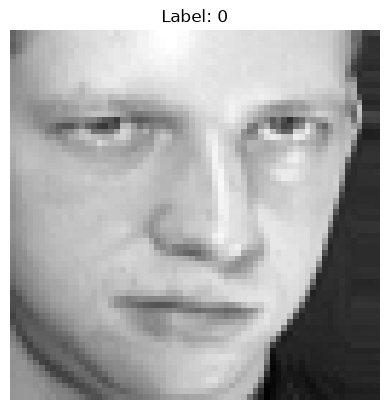

In [38]:
# Showing first persons all 10 images

for i in range(10):
    plt.imshow(X[i].reshape(64,64), cmap='gray')       # image is a flat row of 4096 numbers. imshow needs it in 2D. 4096 = 64 × 64
    plt.title(f"Label: {y[i]}")
    plt.axis('off')
    plt.show()

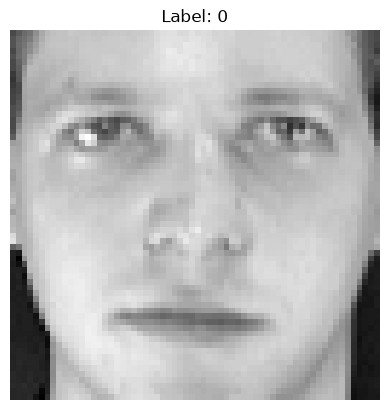

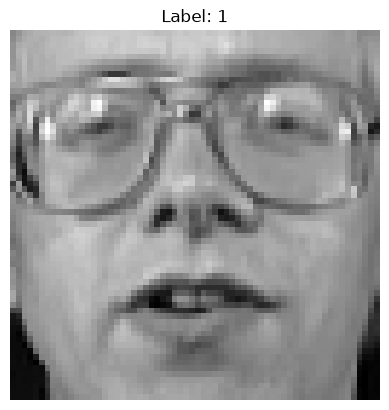

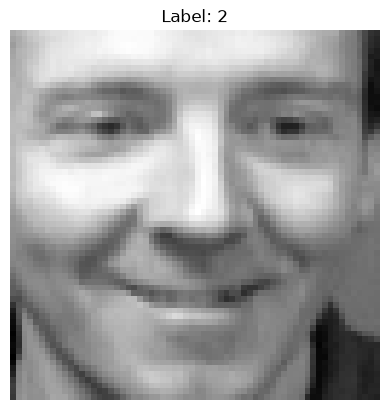

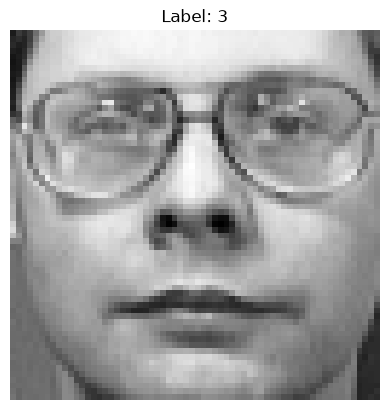

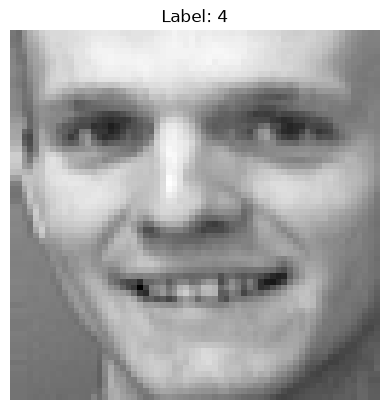

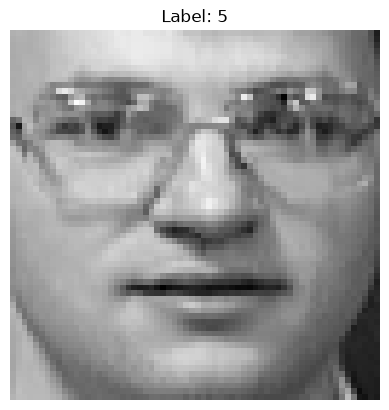

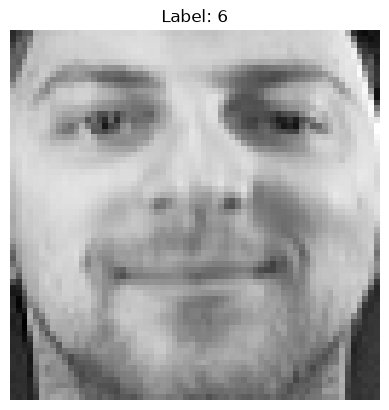

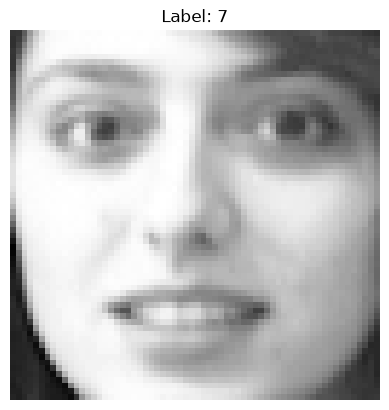

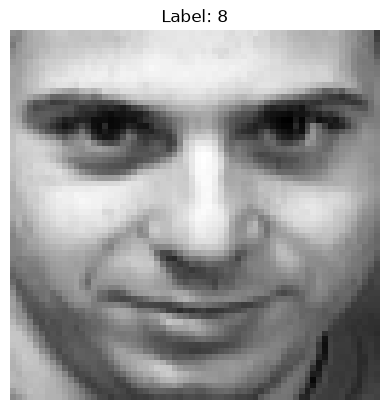

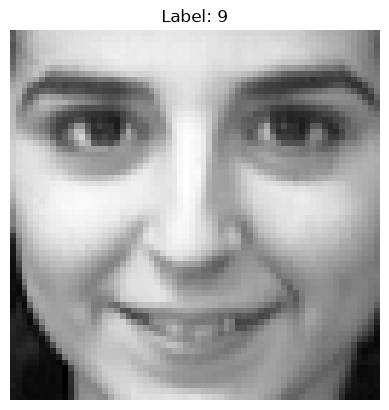

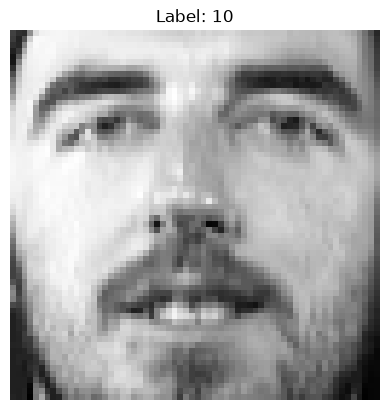

In [42]:
# Showing first 10 persons 1 image

for i in range(0,101,10):
    plt.imshow(X[i].reshape(64,64), cmap='gray')       # image is a flat row of 4096 numbers. imshow needs it in 2D. 4096 = 64 × 64
    plt.title(f"Label: {y[i]}")
    plt.axis('off')
    plt.show()

In [70]:
# Create and save the split

rng = np.random.default_rng(seed)

train_index = []
val_index = []
test_index = []

for person_label in range(40):                         # spliting for each label
    person_index = np.where(y==person_label)[0]        # where returns tuple of index where given label present in y
    person_index = rng.permutation(person_index)
    
    # randomly split the 10 images into 6 train, 2 validation and 2 test images.
    train_index.extend(person_index[:6])
    val_index.extend(person_index[6:8])
    test_index.extend(person_index[8:])

# for proper format
train_index = np.array(train_index)
val_index = np.array(val_index)
test_index = np.array(test_index)

In [73]:
print("Train Split size = ",train_index.shape)
print("Val Split size = ",val_index.shape)
print("Test Split size = ",test_index.shape)

Train Split size =  (240,)
Val Split size =  (80,)
Test Split size =  (80,)


In [75]:
# Save the exact split

np.savez("person_data.npz", train_index=train_index, val_index=val_index, test_index=test_index, seed=seed)

# 2. Load Datasets

In [92]:
# load split

split = np.load("person_data.npz")

train_index = split["train_index"]
val_index = split["val_index"]
test_index = split["test_index"]

# Create the datasets

X_train = X[train_index]
y_train = y[train_index]

X_val = X[val_index]
y_val = y[val_index]

X_test = X[test_index]
y_test = y[test_index]

print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Test set:", X_test.shape)

Training set: (240, 4096)
Validation set: (80, 4096)
Test set: (80, 4096)


**Second test set** by setting the centred 16 × 16 block, rows and columns 24 to 39, to zero of original 64*64 image which is flattened.

In [93]:
"""
    X_test previously of shape(80, 4096)
    creating seprate copy for masking of shape (80, 64, 64) where mask applied on rows and columns at 24 to 39, to zero.
"""
X_test_masked = X_test.reshape(80, 64, 64).copy()
X_test_masked[:, 24:40, 24:40] = 0


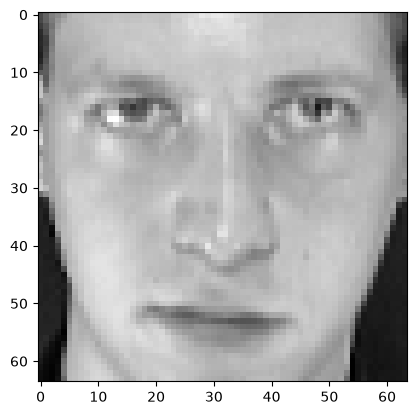

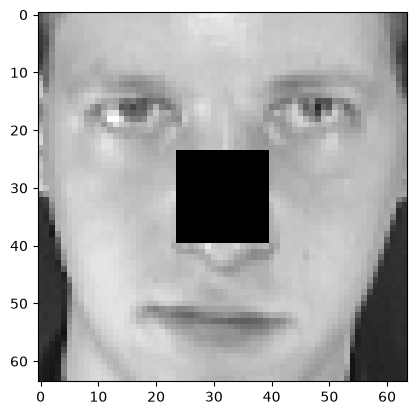

In [91]:
# Display one original and masked face

plt.imshow(X_test[0].reshape(64,64), cmap='gray') 
plt.show()
plt.imshow(X_test_masked[0], cmap='gray') 
plt.show()